In [5]:
import shapely
import geopandas as gpd
import pandas as pd

1. Stwórz warstwę liniową, która po wyświetleniu będzie zawierała pierwsze 3 drukowane litery Twojego imienia i pierwsze 3 drukowane litery Twojego nazwiska. Każda literka powinna być osobnym rekordem w GeoDataFrame. Wyeksportuj te dane i wyświetl w QGIS.

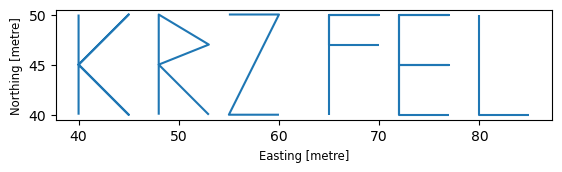

In [37]:
k = LineString([
    (40, 50),
    (40, 45),
    (45, 50),
    (40, 45),
    (45, 40),
    (40, 45),
    (40, 40)
])

r = LineString([
    (48, 40),
    (48, 50),
    (53, 47),
    (48, 45),
    (53, 40)
])

z = LineString([
    (55, 50),
    (60, 50),
    (55, 40),
    (60, 40)
])

f = LineString([
    (65, 40),
    (65, 50),
    (70, 50),
    (65, 50),
    (65, 47),
    (70, 47)
])

e = LineString([
    (72, 40),
    (72, 50),
    (77, 50),
    (72, 50),
    (72, 45),
    (77, 45),
    (72, 45),
    (72, 40),
    (77, 40)
])

l = LineString([
    (80, 50),
    (80, 40),
    (85, 40)
])

litery = gpd.GeoDataFrame(
    {
        "name": ["Literka K", "Literka R", "Literka Z", "Literka F", "Literka E", "Literka L"]
    },
    geometry=[k, r, z, f, e, l],
    crs="EPSG:2180"
)

litery.plot()

litery.to_file("../dane/litery.geojson", driver="GeoJSON")

2. Z danych o wyspach stwórz słownik, gdzie kluczem będą nazwy krajów a wartością lista geometrii wysp do nich przypisanych. Następnie stwórz ranking top 10 krajów które mają największą sumaryczną powierzchnię wysp w m2.

In [3]:
islands = gpd.read_file("../dane/fw2.geojson")
print(islands.crs)

projected = islands.to_crs("EPSG:6933")
islands_dict_m2 = projected.groupby("państwo")["geometry"].apply(list).to_dict()

islands_area_m2 = {
    panstwa: sum(geometry.area for geometry in geometries)
    for panstwa, geometries in islands_dict_m2.items()
}

top_10 = sorted(
    islands_area_m2.items(),
    key=lambda item: item[1],
    reverse=True
)[:10]

pd.DataFrame(
    [(panstwa, round(area)) for panstwa, area in top_10],
    columns=["państwo", "area_m2"]
)

EPSG:4326


,państwo,area_m2
0,Dania (terytorium autonomiczne),2159852903280
1,Kanada,1446178088852
2,Indonezja,899458035984
3,"Indonezja, Papua-Nowa Gwinea",778461165325
4,"Indonezja, Malezja, Brunei",728014157257
5,Madagaskar,587831747287
6,Japonia,322295939826
7,Filipiny,282877737285
8,Nowa Zelandia,263684185493
9,Rosja,254297137709


3. Z danych o wyspach stwórz nowy GeoDataFrame zawierający tylko wyspy należące do Japonii. Przeprowadź dla nich 3 wizualizacje różniące się poziomem uproszczenia geometrii. Dla każdego poziomu wypisz: ilość krawędzi (linii) oraz ilość wierzchołków (punktów) z których się składa.

EPSG:3395
EPSG:3395
        nazwa  line_count
74     Sikoku        6703
207    Honsiu       39474
214  Hokkaido        9444
249    Kiusiu       14970
Total line segments: 70591
        nazwa  vertex_count
74     Sikoku          6704
207    Honsiu         39475
214  Hokkaido          9445
249    Kiusiu         14971
Total vertices: 70595
        nazwa  line_count
74     Sikoku          69
207    Honsiu         419
214  Hokkaido         134
249    Kiusiu         158
Total line segments: 780
        nazwa  vertex_count
74     Sikoku            70
207    Honsiu           420
214  Hokkaido           135
249    Kiusiu           159
Total vertices: 784
        nazwa  line_count
74     Sikoku          36
207    Honsiu         224
214  Hokkaido          71
249    Kiusiu          80
Total line segments: 411
        nazwa  vertex_count
74     Sikoku            37
207    Honsiu           225
214  Hokkaido            72
249    Kiusiu            81
Total vertices: 415
        nazwa  line_count
74   

<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

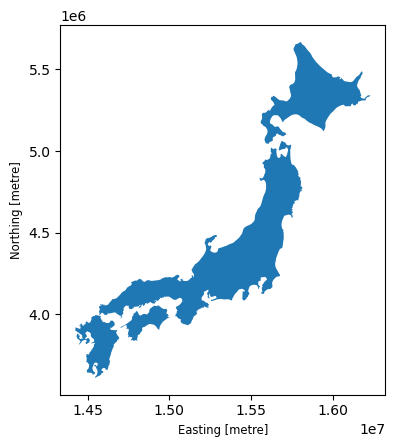

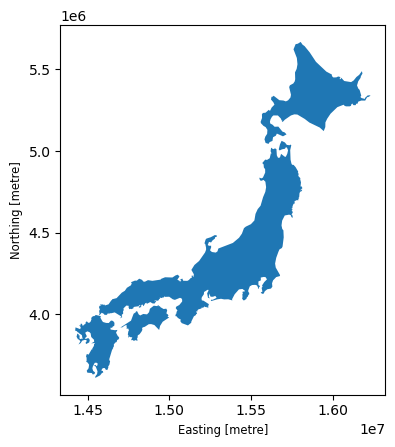

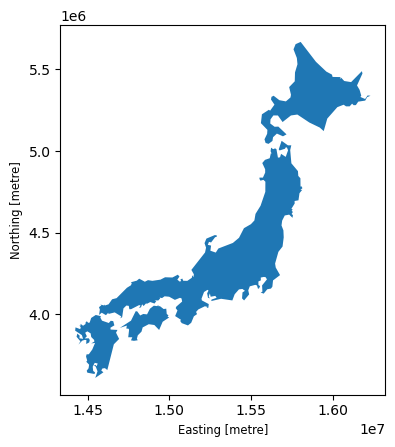

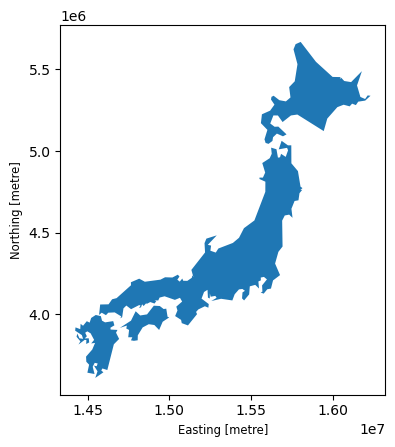

In [37]:
islands["państwo"] = islands["państwo"].str.strip()
print(islands_japan.crs)

islands_japan = islands[islands["państwo"]=="Japonia"]
islands_japan = islands_japan.to_crs("3395")
print(islands_japan.crs)

def count_segments(geom):
    if geom.geom_type == "Polygon":
        rings = [geom.exterior, *geom.interiors]
        return sum(len(ring.coords) - 1 for ring in rings)
    if geom.geom_type == "MultiPolygon":
        return sum(count_segments(poly) for poly in geom.geoms)
    return 0

islands_japan = islands_japan.copy()
islands_japan["line_count"] = islands_japan.geometry.apply(count_segments)
islands_japan["vertex_count"] = islands_japan.geometry.apply(shapely.get_num_coordinates)

print(islands_japan[["nazwa", "line_count"]])
print("Total line segments:", islands_japan["line_count"].sum())
print(islands_japan[["nazwa", "vertex_count"]])
print("Total vertices:", islands_japan["vertex_count"].sum())

islands_japan.plot()

islands_japan_simplified = islands_japan.copy()
islands_japan_simplified["geometry"] = (
    islands_japan_simplified.geometry.simplify(2000, preserve_topology=True)
)

islands_japan_simplified["line_count"] = (
    islands_japan_simplified.geometry.apply(count_segments)
)
islands_japan_simplified["vertex_count"] = (
    islands_japan_simplified.geometry.apply(shapely.get_num_coordinates)
)

print(islands_japan_simplified[["nazwa", "line_count"]])
print("Total line segments:", islands_japan_simplified["line_count"].sum())
print(islands_japan_simplified[["nazwa", "vertex_count"]])
print("Total vertices:", islands_japan_simplified["vertex_count"].sum())

islands_japan_simplified.plot()

islands_japan_simplified2 = islands_japan.copy()
islands_japan_simplified2["geometry"] = (
    islands_japan_simplified2.geometry.simplify(5000, preserve_topology=True)
)

islands_japan_simplified2["line_count"] = (
    islands_japan_simplified2.geometry.apply(count_segments)
)
islands_japan_simplified2["vertex_count"] = (
    islands_japan_simplified2.geometry.apply(shapely.get_num_coordinates)
)

print(islands_japan_simplified2[["nazwa", "line_count"]])
print("Total line segments:", islands_japan_simplified2["line_count"].sum())
print(islands_japan_simplified2[["nazwa", "vertex_count"]])
print("Total vertices:", islands_japan_simplified2["vertex_count"].sum())

islands_japan_simplified2.plot()

islands_japan_simplified3 = islands_japan.copy()
islands_japan_simplified3["geometry"] = (
    islands_japan_simplified3.geometry.simplify(8000, preserve_topology=True)
)

islands_japan_simplified3["line_count"] = (
    islands_japan_simplified3.geometry.apply(count_segments)
)
islands_japan_simplified3["vertex_count"] = (
    islands_japan_simplified3.geometry.apply(shapely.get_num_coordinates)
)

print(islands_japan_simplified3[["nazwa", "line_count"]])
print("Total line segments:", islands_japan_simplified3["line_count"].sum())
print(islands_japan_simplified3[["nazwa", "vertex_count"]])
print("Total vertices:", islands_japan_simplified3["vertex_count"].sum())

islands_japan_simplified3.plot()